<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/Invers%C3%A3o_por_LU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

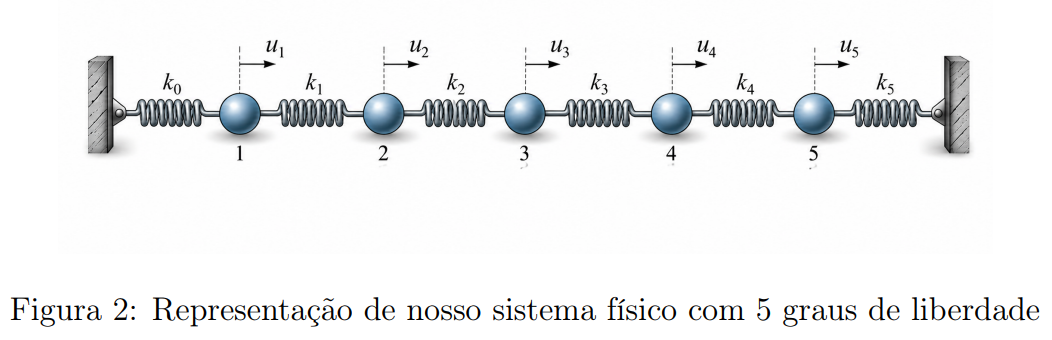

# Atividade Prática: Inversão Matricial por Decomposição LU
**Aplicação à Flexibilidade de uma Estrutura de Molas**
**Disciplina:** Cálculo Numérico Aplicado

---

## Resumo do Trabalho

Este trabalho tem como objetivo determinar numericamente a **matriz de flexibilidade (ou complacência) $C$** de uma estrutura mecânica linear formada por nós e molas em série, por meio da inversão da sua matriz de rigidez $K$ ($C = K^{-1}$).

Para evitar o uso de funções prontas de inversão matricial, a inversa é calculada coluna a coluna empregando o método da **Decomposição $LU$** ($K = L \cdot U$).

---

### Principais Etapas do Desenvolvimento:

1. **Estudo Teórico ($n = 2$):**
   - Montagem e inversão analítica da matriz de rigidez $K$ para um sistema de 2 graus de liberdade.
   - Interpretação física dos coeficientes $C_{ij}$ como o deslocamento do nó $i$ causado por uma força unitária aplicada no nó $j$.

2. **Montagem do Sistema Mecânico ($n = 5$):**
   - Construção da matriz de rigidez tridiagonal $K_{5 \times 5}$ a partir das constantes de rigidez $k_0$ a $k_5$ com extremidades fixas.

3. **Decomposição $LU$:**
   - Fatoração da matriz $K$ nas matrizes triangular inferior $L$ e triangular superior $U$ por Eliminação de Gauss, realizada uma única vez.

4. **Inversão Coluna por Coluna:**
   - Resolução dos sistemas triangulares por substituição progressiva ($L \cdot y_j = e_j$) e regressiva ($U \cdot c_j = y_j$) para cada vetor da base canônica $e_j$, armazenando os vetores $c_j$ nas colunas de $C$.

5. **Validação Numérica e Aplicação:**
   - Verificação da exatidão da inversa avaliando o erro máximo de $K \cdot C \approx I$.
   - Confirmação da simetria da matriz ($C = C^T$).
   - Cálculo direto do vetor de deslocamentos nodais ($u = C \cdot F$) para um vetor de carregamento externo $F$.

In [ ]:
import numpy as np
np.set_printoptions(precision=2, suppress=True, linewidth=100)

# ==============================================================================
# PARTE 1 - EXPERIMENTO TEÓRICO (SISTEMA DE 2 GRAUS DE LIBERDADE)
# ==============================================================================
print("--- PARTE 1: SISTEMA COM 2 GRAUS DE LIBERDADE ---")

# 1. Construir a matriz de rigidez K (2x2)
k0_p1, k1_p1, k2_p1 = 1000.0, 500.0, 1000.0
K_2 = np.array([
    [k0_p1 + k1_p1, -k1_p1],
    [-k1_p1, k1_p1 + k2_p1]
], dtype=float)

print("Matriz K (2x2):\n", K_2)

# 2. Inversão analítica/manual (2x2)
# Fórmula da inversa 2x2: 1/det * adj(K)
det_K2 = K_2[0,0]*K_2[1,1] - K_2[0,1]*K_2[1,0]
C_2 = (1.0 / det_K2) * np.array([
    [K_2[1,1], -K_2[0,1]],
    [-K_2[1,0], K_2[0,0]]
])

print("\nMatriz C (Flexibilidade 2x2):\n", C_2)
print("\nVerificação K * C (Identidade):\n", np.dot(K_2, C_2))


# ==============================================================================
# PARTE 2 e 3 - SISTEMA COM 5 GRAUS DE LIBERDADE E DECOMPOSIÇÃO LU
# ==============================================================================
print("\n" + "="*50)
print("--- PARTE 2 & 3: SISTEMA COM 5 GRAUS DE LIBERDADE ---")

# 4. Construir a matriz K (5x5)
n = 5
k0, k1, k2, k3, k4, k5 = 1200.0, 800.0, 1500.0, 1000.0, 1800.0, 900.0

K = np.array([
    [k0 + k1, -k1,       0.0,        0.0,        0.0],
    [-k1,     k1 + k2,   -k2,        0.0,        0.0],
    [0.0,     -k2,       k2 + k3,    -k3,        0.0],
    [0.0,     0.0,       -k3,        k3 + k4,    -k4],
    [0.0,     0.0,       0.0,        -k4,        k4 + k5]
], dtype=float)

print("\nMatriz K (5x5):\n", K)

# 5. Realizar a decomposição LU (uma única vez)
L = np.eye(n, dtype=float)
U = K.copy()

for k in range(n - 1):
    for i in range(k + 1, n):
        fator = U[i, k] / U[k, k]
        L[i, k] = fator
        for j in range(k + 1, n):
            U[i, j] -= fator * U[k, j]
        U[i, k] = 0.0

print("\nMatriz L:\n", L)
print("\nMatriz U:\n", U)

# Verificação LU ~ K
print("\nErro de decomposição max|LU - K|:", np.max(np.abs(np.dot(L, U) - K)))

# 6 a 9. Inversão coluna por coluna
C = np.zeros((n, n), dtype=float)

for coluna in range(n):
    # (a) Construir vetor unitário e_j
    e = np.zeros(n, dtype=float)
    e[coluna] = 1.0

    # (b) Resolver L * y = e por substituição progressiva
    y = np.zeros(n, dtype=float)
    for i in range(n):
        soma = e[i]
        for j in range(i):
            soma -= L[i, j] * y[j]
        y[i] = soma / L[i, i]

    # (c) Resolver U * x = y por substituição regressiva
    x = np.zeros(n, dtype=float)
    x[n - 1] = y[n - 1] / U[n - 1, n - 1]
    for i in range(n - 2, -1, -1):
        soma = y[i]
        for j in range(i + 1, n):
            soma -= U[i, j] * x[j]
        x[i] = soma / U[i, i]

    # (d) Armazenar x na coluna correspondente de C
    C[:, coluna] = x

print("\nMatriz de Flexibilidade C (5x5):\n", C)


# ==============================================================================
# PARTE 4 - VERIFICAÇÃO NUMÉRICA E APLICAÇÃO
# ==============================================================================
print("\n" + "="*50)
print("--- PARTE 4: VERIFICAÇÃO E APLICAÇÃO ---")

# 10. Verificar KC
M = np.dot(K, C)
I = np.eye(n)
erro_max = np.max(np.abs(M - I))
print(f"\nErro máximo (max|KC - I|): {erro_max:.2e}")

# 11. Verificar simetria
erro_sim = np.max(np.abs(C - C.T))
print(f"Erro de simetria (max|C - C^T|): {erro_sim:.2e}")

# 12. Utilizar a matriz C para calcular deslocamentos
F = np.array([0.0, 100.0, -50.0, 25.0, 0.0], dtype=float)
u = np.dot(C, F)

print("\nVetor de carregamento F (N):\n", F)
print("\nDeslocamentos resultantes u (m):\n", u)

--- PARTE 1: SISTEMA COM 2 GRAUS DE LIBERDADE ---
Matriz K (2x2):
 [[1500. -500.]
 [-500. 1500.]]

Matriz C (Flexibilidade 2x2):
 [[0. 0.]
 [0. 0.]]

Verificação K * C (Identidade):
 [[ 1. -0.]
 [ 0.  1.]]

--- PARTE 2 & 3: SISTEMA COM 5 GRAUS DE LIBERDADE ---

Matriz K (5x5):
 [[ 2000.  -800.     0.     0.     0.]
 [ -800.  2300. -1500.     0.     0.]
 [    0. -1500.  2500. -1000.     0.]
 [    0.     0. -1000.  2800. -1800.]
 [    0.     0.     0. -1800.  2700.]]

Matriz L:
 [[ 1.    0.    0.    0.    0.  ]
 [-0.4   1.    0.    0.    0.  ]
 [ 0.   -0.76  1.    0.    0.  ]
 [ 0.    0.   -0.73  1.    0.  ]
 [ 0.    0.    0.   -0.87  1.  ]]

Matriz U:
 [[ 2000.    -800.       0.       0.       0.  ]
 [    0.    1980.   -1500.       0.       0.  ]
 [    0.       0.    1363.64 -1000.       0.  ]
 [    0.       0.       0.    2066.67 -1800.  ]
 [    0.       0.       0.       0.    1132.26]]

Erro de decomposição max|LU - K|: 0.0

Matriz de Flexibilidade C (5x5):
 [[0. 0. 0. 0. 0.]
 [0. 0.

# Questões para discussão
**a)** Qual é a diferença física entre a matriz de rigidez K e a matriz de flexibilidade C?

**b)** O que representa fisicamente a coluna j da matriz C?

**c)** Por que não é necessário repetir a decomposição LU para cada coluna da inversa?

**d)** Qual é a vantagem computacional de reutilizar as matrizes L e U?

**e)** Por que C deve ser simétrica para o sistema considerado?

**f)** Se uma das molas se tornar muito pouco rígida, o que você espera observar nos
elementos da matriz de flexibilidade?

**g)** Se todas as restrições às extremidades fossem removidas, seria possível inverter a matriz de rigidez? Explique fisicamente e matematicamente.

**h)** Depois de conhecida C, qual é a vantagem de utilizá-la quando desejamos analisar muitos vetores de carregamento diferentes?